<a href="https://colab.research.google.com/github/clickbait-harsh35/ml_project/blob/main/TB_notification_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TB case-notification gaps: profiling States/UTs (Ni-kshay, 2021 and Jan-May 2022)
Clustering + regression case study. Rates per lakh use **Census 2011** populations (`population_census2011.csv`); 2022 covers **Jan-May only**, so 2022 rates are annualised (x12/5) and ratios are used for comparisons across periods.

In [13]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
df = pd.read_csv('RS_Session_257_AU_279_1.csv')
df.columns = ['state','period','target','notified','net','initiated']
df['year'] = df.period.str[:4].astype(int)
pop = pd.read_csv('population_census2011.csv', index_col=0).iloc[:,0]
df['pop'] = df.state.map(pop)
df['rate']  = df.notified*np.where(df.year==2022,12/5,1)/df['pop']*1e5   # per lakh, annualised
df['ach']   = df.notified/df.target*100                                   # % of target
df['init']  = df.initiated/df.net*100                                     # % of net patients started on treatment
w = df.pivot(index='state', columns='year', values=['rate','ach','init'])
w.columns = [f'{a}_{b}' for a,b in w.columns]
w.round(1).sort_values('rate_2021')

,rate_2021,rate_2022,ach_2021,ach_2022,init_2021,init_2022
state,,,,,,
Lakshadweep,18.6,14.9,60.0,50.0,100.0,100.0
Manipur,62.8,90.6,51.2,86.2,92.5,78.3
Kerala,65.5,70.9,78.1,98.7,95.1,93.8
Tripura,69.2,82.2,72.7,86.3,96.1,93.8
Jammu and Kashmir,88.3,98.5,77.3,83.3,93.0,92.3
West Bengal,99.1,112.0,64.6,78.6,95.7,95.4
Ladakh,106.1,118.1,52.0,92.5,96.6,95.7
Tamil Nadu,114.8,130.4,57.1,78.4,95.9,96.3
Karnataka,118.6,127.4,53.7,77.8,96.1,96.3


## Data issues to handle
- **Lakshadweep** (population 64k, 20 cases) and the two **Delhi / Chandigarh** rows are structural outliers: Delhi and Chandigarh are referral hubs that notify patients from neighbouring States, so their per-resident rates (and low net-to-notified ratios) are inflated. They are profiled separately, and the main clustering excludes them.
- Puducherry and DNH&DD also show net patients far below notified cases (transfers out), which is worth noting but they stay in.

   k      SSE  sil_kmeans  sil_ward    ARI
0  2  137.552       0.277     0.248  0.659
1  3  106.044       0.290     0.254  0.723
2  4   81.224       0.305     0.271  0.724
3  5   65.674       0.307     0.290  0.589
4  6   51.617       0.303     0.284  0.854
5  7   45.182       0.277     0.281  0.581
6  8   38.685       0.277     0.258  0.524


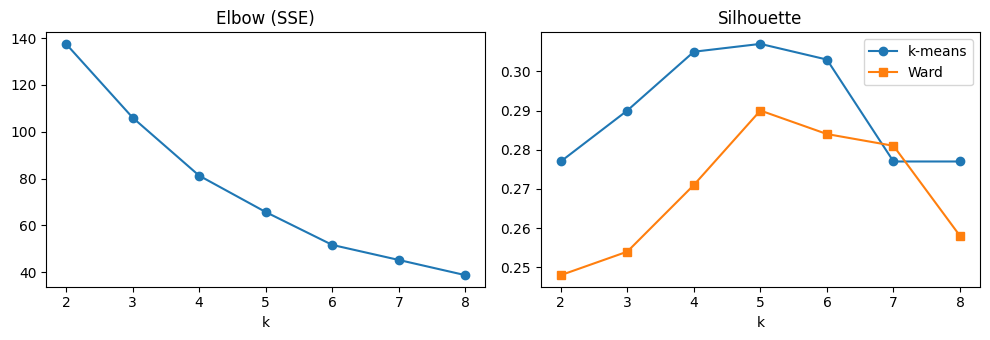

In [ ]:
special = ['Lakshadweep','Delhi','Chandigarh']
feats = ['rate_2021','rate_2022','ach_2021','ach_2022','init_2021','init_2022']
d = w.drop(special)
X = StandardScaler().fit_transform(d[feats])
rows=[]
for k in range(2,9):
    km = KMeans(k, n_init=50, random_state=0).fit(X); hc = AgglomerativeClustering(k, linkage='ward').fit_predict(X)
    rows.append(dict(k=k, SSE=km.inertia_, sil_kmeans=silhouette_score(X,km.labels_), sil_ward=silhouette_score(X,hc), ARI=adjusted_rand_score(km.labels_,hc)))
sel = pd.DataFrame(rows).round(3); print(sel)
fig,ax = plt.subplots(1,2,figsize=(10,3.5))
ax[0].plot(sel.k, sel.SSE, 'o-'); ax[0].set(title='Elbow (SSE)', xlabel='k')
ax[1].plot(sel.k, sel.sil_kmeans, 'o-', label='k-means'); ax[1].plot(sel.k, sel.sil_ward, 's-', label='Ward'); ax[1].set(title='Silhouette', xlabel='k'); ax[1].legend()
plt.tight_layout(); plt.savefig('fig_k_selection.png', dpi=150)

**k = 3 is chosen for interpretability.** Silhouette is flat across k = 3-6 (about 0.29-0.31) and the elbow is gentle, so the data show weak cluster structure; k = 4-5 give marginally higher silhouette but split off singleton or two-State groups. Treat the clusters as a descriptive grouping, not sharply separated types.

In [ ]:
K=3
km = KMeans(K, n_init=50, random_state=0).fit(X); hc = AgglomerativeClustering(K, linkage='ward').fit_predict(X)
print('silhouette k-means', round(silhouette_score(X,km.labels_),3), '| Ward', round(silhouette_score(X,hc),3), '| ARI', round(adjusted_rand_score(km.labels_,hc),2))
d = d.assign(cluster=km.labels_)
prof = d.groupby('cluster')[feats].mean().round(1); prof['n']=d.cluster.value_counts().sort_index(); print(prof)
for c in sorted(d.cluster.unique()): print(c, ', '.join(d.index[d.cluster==c]))

silhouette k-means 0.29 | Ward 0.254 | ARI 0.72
         rate_2021  rate_2022  ach_2021  ach_2022  init_2021  init_2022   n
cluster                                                                    
0            221.8      254.0      73.1      88.0       93.5       93.1   8
1            109.7      125.7      62.3      81.0       95.5       93.8  14
2            184.2      210.7      77.7      95.1       97.3       97.1  11
0 Arunachal Pradesh, Haryana, Maharashtra, Puducherry, Punjab, Rajasthan, Uttar Pradesh, Uttarakhand
1 Assam, Bihar, Chhattisgarh, Goa, Jammu and Kashmir, Karnataka, Kerala, Ladakh, Manipur, Meghalaya, Mizoram, Tamil Nadu, Tripura, West Bengal
2 Andaman and Nicobar Islands, Andhra Pradesh, Dadra and Nagar Haveli and Daman and Diu, Gujarat, Himachal Pradesh, Jharkhand, Madhya Pradesh, Nagaland, Odisha, Sikkim, Telangana


explained variance [0.41 0.28]
     rate_2021  rate_2022  ach_2021  ach_2022  init_2021  init_2022
PC1       0.56       0.56      0.36      0.32       0.17       0.34
PC2      -0.28      -0.27     -0.09      0.10       0.70       0.57


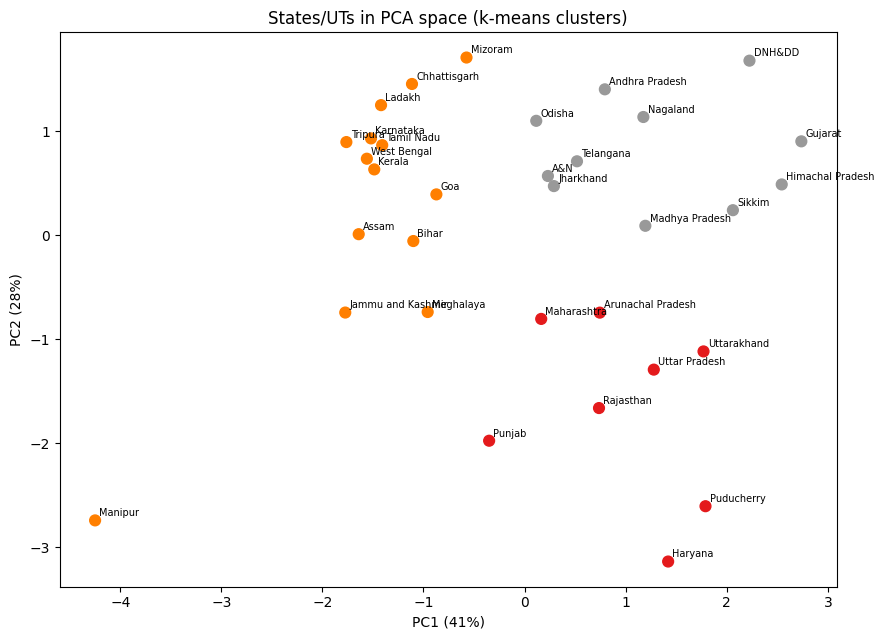

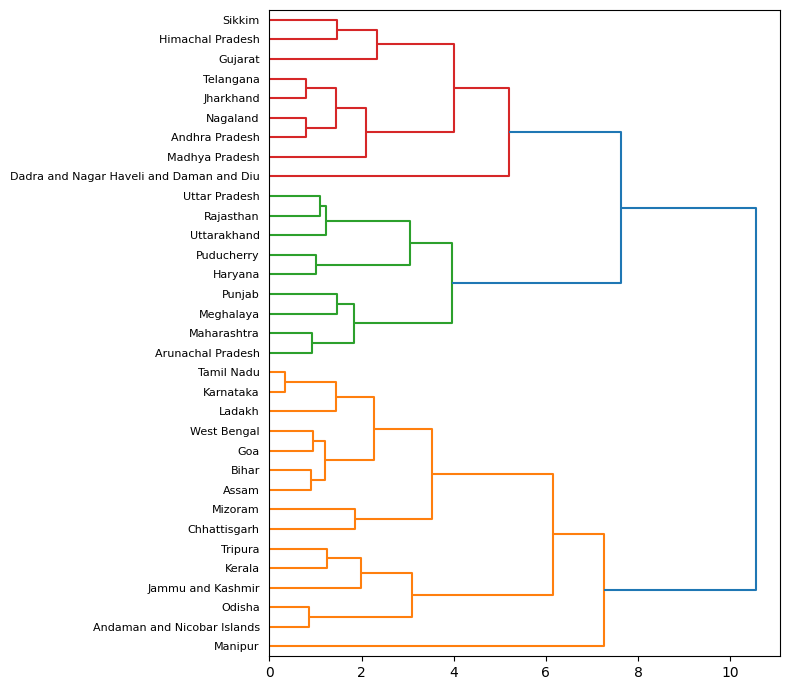

In [ ]:
pca = PCA(2).fit(X); Z = pca.transform(X)
print('explained variance', pca.explained_variance_ratio_.round(2)); print(pd.DataFrame(pca.components_, columns=feats, index=['PC1','PC2']).round(2))
fig,ax = plt.subplots(figsize=(9,6.5))
sc = ax.scatter(Z[:,0],Z[:,1],c=d.cluster,cmap='Set1',s=60)
for i,s in enumerate(d.index): ax.annotate(s.replace('Dadra and Nagar Haveli and Daman and Diu','DNH&DD').replace('Andaman and Nicobar Islands','A&N'),(Z[i,0],Z[i,1]),fontsize=7,xytext=(3,3),textcoords='offset points')
ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.0%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.0%})', title='States/UTs in PCA space (k-means clusters)')
plt.tight_layout(); plt.savefig('fig_pca_clusters.png', dpi=150)
fig,ax = plt.subplots(figsize=(8,7)); dendrogram(linkage(X,'ward'), labels=d.index, orientation='right', ax=ax, leaf_font_size=8); plt.tight_layout(); plt.savefig('fig_dendrogram.png', dpi=150)

In [ ]:
full = w.copy(); full['cluster'] = d.cluster; full['cluster'] = full.cluster.fillna(-1).astype(int)  # -1 = special cases
full.round(2).to_csv('state_clusters.csv'); print(full.loc[special].round(1))

             rate_2021  rate_2022  ach_2021  ach_2022  init_2021  init_2022  \
state                                                                         
Lakshadweep       18.6       14.9      60.0      50.0      100.0      100.0   
Delhi            613.8      705.1      93.7     118.4       86.9       88.2   
Chandigarh       447.2      568.9      62.9      83.4       94.1       94.4   

             cluster  
state                 
Lakshadweep       -1  
Delhi             -1  
Chandigarh        -1  


## Regression: notification rate ~ rural health infrastructre


In [12]:
import os
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.model_selection import cross_val_predict, LeaveOneOut
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
INFRA_FILE = 'infrastructure.csv'          # columns: state, <indicators>
PREDICTORS = ['sc_per_lakh','phc_per_lakh','chc_per_lakh','phc_doctors_per_lakh']   # edit to match your file
if os.path.exists(INFRA_FILE):
    m = w[['rate_2021']].join(pd.read_csv(INFRA_FILE).set_index('state'), how='inner').drop(index=[s for s in special if s in w.index], errors='ignore').dropna()
    Xr, y = m[PREDICTORS], m.rate_2021
    print('VIF', dict(zip(PREDICTORS,[round(variance_inflation_factor(StandardScaler().fit_transform(Xr),i),1) for i in range(len(PREDICTORS))])))
    model = make_pipeline(StandardScaler(), LinearRegression())
    pred = cross_val_predict(model, Xr, y, cv=LeaveOneOut())
    print('LOO-CV  R2 = %.3f  RMSE = %.1f'%(r2_score(y,pred), mean_squared_error(y,pred)**.5))
    model.fit(Xr,y); print('In-sample R2 = %.3f'%model.score(Xr,y), dict(zip(PREDICTORS, model[-1].coef_.round(1))))
    m['residual'] = y - model.predict(Xr); print(m.residual.sort_values().head(8))   # most negative = notifying less than infrastructure predicts
else:
    print('infrastructure.csv not found: add it to run the regression.')

VIF {'sc_per_lakh': np.float64(3.5), 'phc_per_lakh': np.float64(4.4), 'chc_per_lakh': np.float64(2.3), 'phc_doctors_per_lakh': np.float64(3.9)}
LOO-CV  R2 = -0.133  RMSE = 60.9
In-sample R2 = 0.153 {'sc_per_lakh': np.float64(-8.6), 'phc_per_lakh': np.float64(19.0), 'chc_per_lakh': np.float64(4.4), 'phc_doctors_per_lakh': np.float64(-29.1)}
state
Jammu and Kashmir   -86.824367
Tripura             -74.755459
West Bengal         -74.100973
Kerala              -68.827669
Manipur             -57.262656
Karnataka           -55.909918
Odisha              -55.762172
Chhattisgarh        -52.914061
Name: residual, dtype: float64
